# ATNLP 2026-2027
Building GPT-2 from scratch.
___


* After you are done with this notebook, copy the full model code into a `transformers.py` file, so that you can import the model and sub-parts more easily for other tasks.

In [10]:
import math
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

## Task 1.1: Scaled Dot-Product Attention and Causal Multi-Head Self-Attention
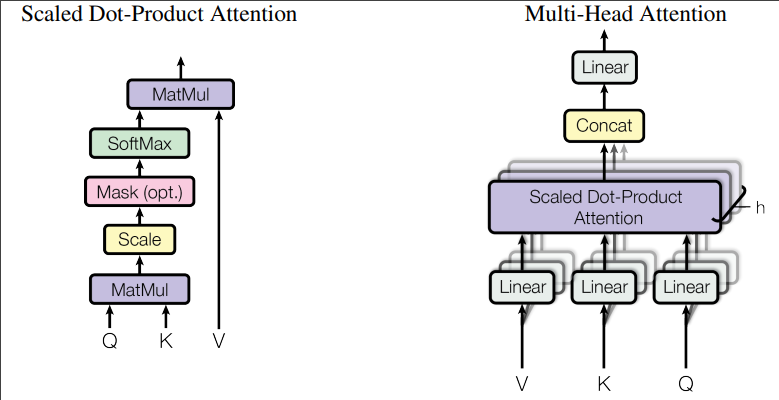

*Scaled dot-product attention and multi-head attention, from Figure 2 of [Vaswani et al., 2017](https://arxiv.org/abs/1706.03762).*

We will start by implementing Multi-Head Attention, which combines multiple scaled dot-product attention (SDPA) heads. We can calculate all heads in parallel by reshaping our tensors, so we don't need to loop over the individual heads.

In GPT-2, we use *self-attention*: query, key, and value all come from the same input sequence. We also need to make this attention *causal*. Each token can attend to itself and all previous tokens, but is not allowed to see any future tokens. Otherwise, our model could look at the answers while learning to predict the next token.

In order to have trainable parameters, we can build all modules using torch's `nn.Module` functionality.

* Our module's `__init__()` method takes in the embedding dimension `emb_dim`, the number of heads `num_heads`, and a dropout rate `dropout`.
    * Make sure that `emb_dim` is divisible by `num_heads`, and store `head_dim = emb_dim // num_heads`
* We create 2 linear layers
    * GPT-2 computes query, key, and value together with one linear layer of size `(emb_dim, 3 * emb_dim)`
        * We will split its output into the three tensors afterwards
    * The output linear layer takes `emb_dim` as input size, and outputs `emb_dim` again
    * Both linear layers include a bias
* We also create two dropout layers
    * one for the attention probabilities, and one for the output of the output linear layer
    * Use the given `dropout` rate for both
* The `forward()` method of this module takes in the batched sequence input `x`, and an optional padding `mask`, and performs the calculations of the following formula:
    * 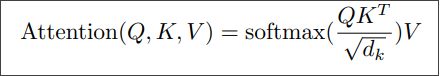
    * Remember that our input at this stage has dimensions `(batch_size, seq_len, emb_dim)`
    * We pass `x` through the combined query, key, and value projection, and split its output into `Q`, `K`, and `V`
    * Then, we perform the multi-head splitting of the linearly projected outputs
        * each projection's hidden dimension has to be reshaped to fit the `num_heads` and `head_dim` structure (in that order)
        * Hint: Both `batch_size` and `seq_len` shouldn't be changed
    * Afterwards, we perform the matrix multiplication step of queries with their transposed keys, visualized by the $QK^T$ in the above formula
    * Hint: The output shape after this step should be `(batch_size, num_heads, seq_len, seq_len)`
    * Divide this result by the square root of our `head_dim`, and call it `key_out`
    * After this step, mask the `key_out` tensor so that each token can only attend to itself and previous tokens
        * If a padding mask is provided, also exclude the padding positions
        * The padding mask has shape `(batch_size, 1, 1, seq_len)`, with `1` for real tokens and `0` for padding
        * Masked entries should receive zero probability after softmax
    * Following this, we perform the softmax step on the scaled and masked `key_out`
        * Make sure to apply softmax to the correct dimension
    * Apply attention dropout to the result
    * Now we just need to matrix multiply this result with the values (which were passed through the linear projection earlier)
    * Reshape it to fit the input shape of our output linear layer
    * Pass it through the output linear layer and apply output dropout

We will add the residual connection and layer normalization when building the GPT-2 block in the next task.


In [11]:
class MultiHeadAttention(nn.Module):
    def __init__(self, emb_dim, num_heads, dropout=0.1):
        super().__init__()

        assert emb_dim % num_heads == 0, "emb_dim must be divisible by num_heads"
        self.emb_dim = emb_dim
        self.num_heads = num_heads
        self.head_dim = emb_dim // num_heads

        self.linear_qkv = nn.Linear(emb_dim, 3 * emb_dim)
        self.linear_out = nn.Linear(emb_dim, emb_dim)

        self.attn_dropout = nn.Dropout(dropout)
        self.out_dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, _ = x.shape


        q, k, v = self.linear_qkv(x).split(self.emb_dim, dim=-1)
        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)


        key_out = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)

        allowed = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device))
        allowed = allowed.view(1, 1, T, T)
        if mask is not None:
            allowed = allowed & mask.bool()
        key_out = key_out.masked_fill(~allowed, torch.finfo(key_out.dtype).min)

        attn = F.softmax(key_out, dim=-1)
        attn = self.attn_dropout(attn)


        out = attn @ v
        out = out.transpose(1, 2).contiguous().view(B, T, self.emb_dim)
        out = self.out_dropout(self.linear_out(out))
        return out


## Task 1.2: Transformer Blocks
We will now create Transformer Blocks out of our `MultiHeadAttention` module, combined with Feedforward-Networks.

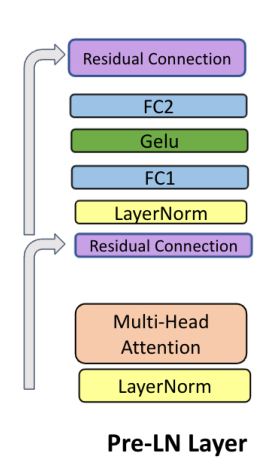

*Pre-LN transformer layer, from Figure 1 (left) of [Shleifer et al., 2021](https://arxiv.org/abs/2110.09456).*

GPT-2 uses *pre-layer normalization*: we normalize the input before running it through attention or the feedforward network. We then use skip-connections to add each result back to the input of its stage.

* To create the blocks, our module takes as input in its `__init__` method:
    * the embedding dimension `emb_dim`, the number of heads `num_heads`, and a dropout rate `dropout`
    * we initialize our `MultiHeadAttention` module using these arguments
    * in the `__init__` method, we further need two `nn.LayerNorm` objects with an epsilon parameter `eps=1e-5`
    * then, still in the `__init__` method, we set up the feedforward network
        * GPT-2 uses a hidden dimension of `forward_dim = 4 * emb_dim`
    * we build it by creating an `nn.Sequential` module and filling it with:
        * a linear layer projecting the input onto the `forward_dim`
        * running it through `nn.GELU` with `approximate="tanh"`, which is the GELU version used by GPT-2
        * and projecting the `forward_dim` back to the embedding dimension with another linear layer
        * a dropout layer using the given `dropout` rate
* the `forward()` method takes the batched sequence input `x` and an optional padding `mask`
    * first, normalize the input using our first layer norm, and run it through multi-head attention together with the mask
    * secondly, we build a skip-connection by adding the original input back to the output of multi-head attention
    * third, normalize this result using our second layer norm, and put it through our FFN
    * fourth, we build another skip-connection by adding the result from the second step onto the output of the FFN
    * return the result


In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, emb_dim, num_heads, dropout):
        super().__init__()

        # Multi-head attention built from the given arguments.
        # Must be called `mha`: initialize_gpt2_weights accesses layer.mha.linear_out
        self.mha = MultiHeadAttention(emb_dim, num_heads, dropout)

        # Two separate LayerNorms with eps=1e-5 (each has its own learnable weight and bias)
        self.ln1 = nn.LayerNorm(emb_dim, eps=1e-5)   # applied before attention
        self.ln2 = nn.LayerNorm(emb_dim, eps=1e-5)   # applied before the FFN

        # GPT-2 uses a hidden dimension of 4 * emb_dim in the feedforward network
        forward_dim = 4 * emb_dim

        # Feedforward network. Must be called `ffn` and keep this order:
        # initialize_gpt2_weights accesses layer.ffn[2] (the second Linear layer)
        self.ffn = nn.Sequential(
            nn.Linear(emb_dim, forward_dim),   # [0] project up to forward_dim
            nn.GELU(approximate="tanh"),       # [1] GELU variant used by GPT-2
            nn.Linear(forward_dim, emb_dim),   # [2] project back down to emb_dim
            nn.Dropout(dropout),               # [3] dropout with the given rate
        )

    def forward(self, x, mask=None):
        # normalize inside each residual branch
        # Step 1 + 2: LayerNorm -> attention (with mask), then add the original input back
        x = x + self.mha(self.ln1(x), mask)

        # Step 3 + 4: LayerNorm -> FFN, then add the result of step 2 back
        x = x + self.ffn(self.ln2(x))

        return x

This already finishes the main building block of GPT-2. We now just need to pack it into an appropriate format so that it can take input sequences and predict the next token. To achieve this, we create another module called `GPT2`.

## Task 1.3: GPT-2
* The `GPT2` takes as input in its `__init__` method:
    * the vocabulary size `vocab_size`, embedding dimension `emb_dim`, number of layers `num_layers`, number of heads `num_heads`, the dropout rate `dropout`, and the maximum sequence length `max_len`
    * Note that our input sequences must fit into the maximum allowed length. For the small debugging task below, we will create sequences which already satisfy this.
    * We then define
        * the token level embeddings with dimensions `vocab_size x emb_dim`
        * learned absolute position embeddings with dimensions `max_len x emb_dim`
            * These are another `nn.Embedding` layer, and are trained together with the rest of the model
            * They represent each token's position in the input sequence
        * a dropout layer
        * instantiate `num_layers` many `TransformerBlock` modules inside an `nn.ModuleList`
        * a final `nn.LayerNorm` with `eps=1e-5`, which normalizes the output after the last block
        * a linear output layer which maps the embedding dimension back to the vocabulary size, without a bias
    * GPT-2 also uses a specific weight initialization, which we provide below
        * Call `initialize_gpt2_weights` on the model after creating its layers
        * The output layer then needs to share its weight parameter with the token embeddings
            * This is called *weight tying*: the same learned vectors are used to represent input tokens and to score possible next tokens
            * Both layers should use the same parameter, so that updates from either side affect the shared weights
* In the `forward()` method, we take in the batched sequence inputs, as well as an optional padding mask
    * Remember that the input at this stage has dimensions `(batch_size, seq_len)`
    * Then, we create the input to the position embeddings by defining the index of each token in the sequence
        * Move the positions to the device on which the batched sequences are located
        * The first position has index `0`
    * We then run our input through the token embeddings, the above created positions are run through the position embeddings, and both results are summed up
    * Apply dropout to the summed up result
    * This will be the input to our first transformer block
        * loop through all layers by passing the previous output as input through the next layer, together with the padding mask
    * Run the last output through the final layer norm and the linear output layer
    * Return the logits, which have dimensions `(batch_size, seq_len, vocab_size)`
        * Each position predicts the next token in the sequence
        * We don't apply softmax here, as this is already handled by the cross-entropy loss during training

The initialization below uses small random weights, with smaller weights for the residual output projections to account for the depth of the model. You don't need to implement this function yourself.


In [13]:
def initialize_gpt2_weights(model):
    def initialize_module(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    model.apply(initialize_module)

    # two residual branches per transformer block
    residual_std = 0.02 / math.sqrt(2 * len(model.layers))
    for layer in model.layers:
        nn.init.normal_(layer.mha.linear_out.weight, mean=0.0, std=residual_std)
        nn.init.normal_(layer.ffn[2].weight, mean=0.0, std=residual_std)


In [14]:
class GPT2(nn.Module):
    def __init__(
        self,
        vocab_size,
        emb_dim=768,
        num_layers=12,
        num_heads=12,
        dropout=0.1,
        max_len=1024,
    ):
        super().__init__()

        self.max_len = max_len

        # token and learned absolute position embeddings
        self.token_emb = nn.Embedding(vocab_size, emb_dim)
        self.pos_emb = nn.Embedding(max_len, emb_dim)
        self.dropout = nn.Dropout(dropout)

        # stack of transformer blocks (must be named `layers`)
        self.layers = nn.ModuleList(
            [TransformerBlock(emb_dim, num_heads, dropout) for _ in range(num_layers)]
        )

        # final layer norm and output projection (no bias)
        self.ln_f = nn.LayerNorm(emb_dim, eps=1e-5)
        self.linear_out = nn.Linear(emb_dim, vocab_size, bias=False)

        # GPT-2 weight initialization, then weight tying
        initialize_gpt2_weights(self)
        self.linear_out.weight = self.token_emb.weight

    def forward(self, x, mask=None):
        # x: (batch_size, seq_len)
        B, T = x.shape
        assert T <= self.max_len, f"sequence length {T} exceeds max_len {self.max_len}"

        # positions 0..T-1 on the same device as the input
        positions = torch.arange(T, device=x.device)

        # token + position embeddings, then dropout: (B, T, emb_dim)
        h = self.dropout(self.token_emb(x) + self.pos_emb(positions))

        # pass through all transformer blocks with the padding mask
        for layer in self.layers:
            h = layer(h, mask)

        # final layer norm and projection to vocabulary: (B, T, vocab_size)
        h = self.ln_f(h)
        logits = self.linear_out(h)

        return logits


That's it - you made it! We now have a GPT-2 architecture, which we can also run with fewer layers and smaller embeddings for our debugging task.

Below, we will check the output shape and train the model on a small synthetic task.


### Test case 1: Shape check
The first test simply checks that your GPT-2 model produces the expected output shape given a batch of input sequences.
It doesn't train the model, it just verifies that all layers connect properly and return tensors of the right size.

For each input position, we should get one logit for each token in the vocabulary. The output shape should therefore be `(batch_size, seq_len, vocab_size)`.

We use a small model here, so that the check can also run quickly on a CPU.

If the asserted shape passes, you are on the right track.


In [15]:
# general test case 1
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = GPT2(
    vocab_size=200,
    emb_dim=64,
    num_layers=2,
    num_heads=4,
    dropout=0.0,
    max_len=128,
).to(device)
model.eval()

# input: batch size 4, sequence length of 80
x = torch.randint(0, 200, (4, 80)).to(device)

# expected output shape of the model
expected_out_shape = torch.Size([4, 80, 200])

with torch.no_grad():
    out = model(x)

assert out.shape == expected_out_shape, f"wrong output shape, expected: {expected_out_shape}"


### Test Case 2: Training for a simple copy task

Next, we test whether your GPT-2 model can learn to copy a sequence.
This is a minimal synthetic task that checks if your model is able to learn a very easy task.

We put the original sequence and its copy into one sequence, with a separator token `SEP` between them. After seeing the separator, the model should predict the original tokens again, followed by an end token `EOS`.

Example:

```
input:  [BOS, 12, 7, 5, 9, SEP, 12, 7, 5, 9]
target: [  -,  -, -, -, -,  12,  7, 5, 9, EOS]
```

The targets are shifted by one position: the output at `SEP` should predict the first copied token. The `-` entries are ignored when calculating the loss, as the random original sequence cannot be predicted from the previous tokens.

We use teacher forcing here, so previous tokens of the copy are given as input during both training and validation. Loss and token accuracy are calculated over the copied tokens and `EOS` only. Padding is also ignored.

We provide the required code below, using short sequences and a small model. If your GPT-2 is implemented correctly, it should learn to copy the sequences with near-100% token accuracy.


In [16]:
from torch.utils.data import Dataset, DataLoader

# minimal config
random.seed(42)
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cpu':
    # small tensors can run faster with fewer CPU threads
    torch.set_num_threads(2)

V = 32
PAD = 0
BOS = 1
SEP = 2
EOS = 3
IGNORE = -100
MIN_LEN = 3
MAX_LEN = 6
TRAIN_SAMPLES = 4096
VAL_SAMPLES = 256
BATCH_SIZE = 64
NUM_WORKERS = 0

# synthetic copy dataset
class CopyDataset(Dataset):
    def __init__(self, n_samples):
        self.samples = []
        for _ in range(n_samples):
            L = random.randint(MIN_LEN, MAX_LEN)

            # tokens in [4..V-1], the other indices are reserved
            seq = torch.randint(4, V, (L,), dtype=torch.long)
            self.samples.append(seq)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


def collate_fn(batch):
    # full sequence: BOS + original sequence + SEP + copy + EOS
    # inputs and targets are shifted by one position
    max_len = 2 * max(seq.size(0) for seq in batch) + 2
    inputs = torch.full((len(batch), max_len), PAD, dtype=torch.long)
    targets = torch.full((len(batch), max_len), IGNORE, dtype=torch.long)

    for i, seq in enumerate(batch):
        L = seq.size(0)
        full_seq = torch.cat([
            torch.tensor([BOS]), seq, torch.tensor([SEP]), seq, torch.tensor([EOS])
        ])
        n = full_seq.size(0) - 1
        inputs[i, :n] = full_seq[:-1]

        # supervise only the copy and EOS; the random prefix cannot be predicted
        targets[i, L + 1:n] = full_seq[L + 2:]

    # padding mask: [B, 1, 1, seq_len]
    mask = (inputs != PAD).unsqueeze(1).unsqueeze(2)
    return inputs, targets, mask


In [17]:
def tokens_accuracy(logits, targets, ignore_idx=IGNORE):
    # logits: [B, seq_len, V], targets: [B, seq_len]
    preds = logits.argmax(dim=-1)
    mask = targets != ignore_idx
    correct = ((preds == targets) & mask).sum().item()
    total = mask.sum().item()

    return correct / max(1, total)


@torch.no_grad()
def eval_loop():
    model.eval()
    total_loss, total_acc, total_tokens = 0.0, 0.0, 0

    for inputs, targets, mask in val_dl:
        inputs, targets, mask = inputs.to(device), targets.to(device), mask.to(device)
        logits = model(inputs, mask)

        loss = criterion(logits.reshape(-1, V), targets.reshape(-1))
        n_tokens = (targets != IGNORE).sum().item()
        total_loss += loss.item() * n_tokens
        total_acc += tokens_accuracy(logits, targets) * n_tokens
        total_tokens += n_tokens

    return total_loss / total_tokens, total_acc / total_tokens


Example training progression (small deviations are always possible). The random seed is fixed, but results can still differ between devices:

```
Epoch 1 done | train_loss 2.7084 | val_loss 1.8584 | val_tok_acc 62.54%
Epoch 2 done | train_loss 1.0144 | val_loss 0.4891 | val_tok_acc 94.30%
Epoch 3 done | train_loss 0.3018 | val_loss 0.1756 | val_tok_acc 98.61%
Epoch 4 done | train_loss 0.1214 | val_loss 0.0862 | val_tok_acc 99.44%
Epoch 5 done | train_loss 0.0572 | val_loss 0.0387 | val_tok_acc 100.00%
Epoch 6 done | train_loss 0.0277 | val_loss 0.0225 | val_tok_acc 100.00%
Epoch 7 done | train_loss 0.0185 | val_loss 0.0168 | val_tok_acc 100.00%
Epoch 8 done | train_loss 0.0141 | val_loss 0.0130 | val_tok_acc 100.00%
Epoch 9 done | train_loss 0.0112 | val_loss 0.0105 | val_tok_acc 100.00%
Epoch 10 done | train_loss 0.0091 | val_loss 0.0086 | val_tok_acc 100.00%
Epoch 11 done | train_loss 0.0076 | val_loss 0.0072 | val_tok_acc 100.00%
Epoch 12 done | train_loss 0.0064 | val_loss 0.0062 | val_tok_acc 100.00%
Epoch 13 done | train_loss 0.0055 | val_loss 0.0054 | val_tok_acc 100.00%
Epoch 14 done | train_loss 0.0048 | val_loss 0.0046 | val_tok_acc 100.00%
Epoch 15 done | train_loss 0.0042 | val_loss 0.0041 | val_tok_acc 100.00%
```


In [18]:
train_ds = CopyDataset(TRAIN_SAMPLES)
val_ds = CopyDataset(VAL_SAMPLES)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=NUM_WORKERS)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)

model = GPT2(
    vocab_size=V,
    emb_dim=64,
    num_layers=2,
    num_heads=4,
    dropout=0.0,
    max_len=2 * MAX_LEN + 2,
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, total_tokens = 0.0, 0

    for inputs, targets, mask in train_dl:
        inputs, targets, mask = inputs.to(device), targets.to(device), mask.to(device)
        optimizer.zero_grad()

        logits = model(inputs, mask)
        loss = criterion(logits.reshape(-1, V), targets.reshape(-1))
        loss.backward()
        optimizer.step()

        n_tokens = (targets != IGNORE).sum().item()
        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens

    val_loss, val_acc = eval_loop()
    print(f"Epoch {epoch} done | train_loss {total_loss / total_tokens:.4f} | val_loss {val_loss:.4f} | val_tok_acc {val_acc*100:.2f}%")


Epoch 1 done | train_loss 2.7084 | val_loss 1.8584 | val_tok_acc 62.54%
Epoch 2 done | train_loss 1.0143 | val_loss 0.4891 | val_tok_acc 94.37%
Epoch 3 done | train_loss 0.3024 | val_loss 0.1771 | val_tok_acc 98.68%
Epoch 4 done | train_loss 0.1175 | val_loss 0.0700 | val_tok_acc 99.93%
Epoch 5 done | train_loss 0.0821 | val_loss 0.0718 | val_tok_acc 99.24%
Epoch 6 done | train_loss 0.0374 | val_loss 0.0254 | val_tok_acc 99.93%
Epoch 7 done | train_loss 0.0190 | val_loss 0.0168 | val_tok_acc 100.00%
Epoch 8 done | train_loss 0.0141 | val_loss 0.0131 | val_tok_acc 100.00%
Epoch 9 done | train_loss 0.0113 | val_loss 0.0107 | val_tok_acc 100.00%
Epoch 10 done | train_loss 0.0092 | val_loss 0.0088 | val_tok_acc 100.00%
Epoch 11 done | train_loss 0.0077 | val_loss 0.0075 | val_tok_acc 100.00%
Epoch 12 done | train_loss 0.0066 | val_loss 0.0064 | val_tok_acc 100.00%
Epoch 13 done | train_loss 0.0057 | val_loss 0.0055 | val_tok_acc 100.00%
Epoch 14 done | train_loss 0.0049 | val_loss 0.0048 |